In [ ]:
# --- Step 0: Install required packages ---
!pip install -q tf-keras-vis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.2 MB/s eta 0:00:00


In [ ]:
# --- Step 1: Upload kaggle.json and setup Kaggle API ---
from google.colab import files
uploaded = files.upload()  # Upload kaggle.json here
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
# --- Step 2: Download and unzip GTSRB dataset ---
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
!unzip -q gtsrb-german-traffic-sign.zip -d GTSRB_dataset

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
 99% 603M/612M [00:04<00:00, 45.3MB/s]
100% 612M/612M [00:04<00:00, 154MB/s] 


In [ ]:
# --- Step 3: Prepare data generators ---
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMAGE_SIZE = (25, 25)  # Your specified size
BATCH_SIZE = 32

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_generator = datagen.flow_from_directory(
    './GTSRB_dataset/Train',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    './GTSRB_dataset/Train',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [ ]:
# --- Step 4: Define your CNN model ---
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dropout, Flatten, Dense

def create_model(input_shape):
    model = Sequential()
    model.add(Conv2D(32, (5,5), activation='relu', input_shape=input_shape))
    model.add(Conv2D(32, (5,5), activation='relu'))
    model.add(MaxPool2D((2,2)))
    model.add(Dropout(0.25))
    model.add(Conv2D(64, (3,3), activation='relu'))
    model.add(Conv2D(64, (3,3), activation='relu'))
    model.add(MaxPool2D((2,2)))
    model.add(Dropout(0.25))
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(43, activation='softmax'))
    return model

input_shape = IMAGE_SIZE + (3,)
model = create_model(input_shape)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# --- Step 5: Train the model ---
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator
)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


981/981 ━━━━━━━━━━━━━━━━━━━━ 97s 96ms/step - accuracy: 0.3061 - loss: 2.5260 - val_accuracy: 0.8217 - val_loss: 0.5891
Epoch 2/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 93s 95ms/step - accuracy: 0.8345 - loss: 0.5168 - val_accuracy: 0.8824 - val_loss: 0.3711
Epoch 3/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 93s 95ms/step - accuracy: 0.9063 - loss: 0.2994 - val_accuracy: 0.9170 - val_loss: 0.2537
Epoch 4/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 93s 95ms/step - accuracy: 0.9321 - loss: 0.2155 - val_accuracy: 0.9316 - val_loss: 0.2217
Epoch 5/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 97s 99ms/step - accuracy: 0.9415 - loss: 0.1869 - val_accuracy: 0.9342 - val_loss: 0.2017
Epoch 6/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 93s 95ms/step - accuracy: 0.9524 - loss: 0.1501 - val_accuracy: 0.9444 - val_loss: 0.1834
Epoch 7/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 93s 95ms/step - accuracy: 0.9597 - loss: 0.1324 - val_accuracy: 0.9441 - val_loss: 0.1785
Epoch 8/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 93s 95ms/step - accuracy: 0.9630 - loss: 0.1243 - val_accurac

In [ ]:
# --- Step 6: Upload a custom (original) image for testing ---
uploaded_img = files.upload()  # Upload your test (original) image here

import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

Saving 00014_00001_00024.png to 00014_00001_00024.png


In [ ]:
# load the first uploaded file as the original image
img_path = next(iter(uploaded_img.keys()))
img = load_img(img_path, target_size=IMAGE_SIZE)
x = img_to_array(img) / 255.0
x = np.expand_dims(x, axis=0)

In [ ]:
# --- Step 7: Predict on uploaded original image (optional) ---
pred_probs = model.predict(x)[0]
pred_class_idx = np.argmax(pred_probs)
# If you want the class label:
pred_class_label = list(train_generator.class_indices.keys())[pred_class_idx]
pred_score = pred_probs[pred_class_idx]

print(f"Predicted class (original image): {pred_class_label} with confidence {pred_score:.2f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
Predicted class (original image): 14 with confidence 1.00


In [ ]:
# --- NEW Step 8: Upload adversarial image from system (instead of generating via FGSM) ---
print("\nNow upload the adversarial image (should be same size or will be resized to IMAGE_SIZE):")
uploaded_adv = files.upload()  # Upload your adversarial image here

adv_path = next(iter(uploaded_adv.keys()))
adv_img = load_img(adv_path, target_size=IMAGE_SIZE)
adv_x = img_to_array(adv_img) / 255.0
adv_x = np.expand_dims(adv_x, axis=0)


Now upload the adversarial image (should be same size or will be resized to IMAGE_SIZE):


Saving Adversarial image with flipped targeted class.PNG to Adversarial image with flipped targeted class.PNG


In [ ]:
# Convert adversarial image to tensor for saliency function usage
adversarial_x = tf.convert_to_tensor(adv_x, dtype=tf.float32)

In [ ]:
# --- Step 9: Utility functions for saliency, perturbation, and overlay ---
import matplotlib.pyplot as plt

def generate_saliency_map(model, input_image, class_idx):
    input_image = tf.cast(input_image, tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(input_image)
        preds = model(input_image)
        loss = preds[:, class_idx]
    grads = tape.gradient(loss, input_image)
    saliency = tf.reduce_max(tf.abs(grads), axis=-1)[0]
    saliency = (saliency - tf.reduce_min(saliency)) / (tf.reduce_max(saliency) - tf.reduce_min(saliency) + 1e-10)
    return saliency.numpy()

def generate_perturbation_map(original_img, adversarial_img):
    perturbation = np.abs(adversarial_img - original_img)
    perturbation_map = np.max(perturbation, axis=-1)
    perturbation_map = (perturbation_map - perturbation_map.min()) / (perturbation_map.max() - perturbation_map.min() + 1e-10)
    return perturbation_map

def overlay_heatmap_on_image(image, heatmap, alpha=0.5, cmap='jet'):
    import matplotlib.cm as cm
    heatmap_color = cm.get_cmap(cmap)(heatmap)[:, :, :3]
    heatmap_color = tf.image.resize(heatmap_color, (image.shape[0], image.shape[1])).numpy()
    overlay_img = alpha * heatmap_color + (1 - alpha) * image
    overlay_img = np.clip(overlay_img, 0, 1)
    return overlay_img

In [ ]:
# --- Step 10: Generate saliency maps and perturbation map ---
# Use the original predicted class index (pred_class_idx) for saliency comparison.
saliency_orig = generate_saliency_map(model, x, pred_class_idx)
saliency_adv = generate_saliency_map(model, adversarial_x, pred_class_idx)

perturbation_map = generate_perturbation_map(x[0], adversarial_x[0].numpy())

overlay_orig = overlay_heatmap_on_image(x[0], saliency_orig)
overlay_adv = overlay_heatmap_on_image(adversarial_x[0].numpy(), saliency_adv)
overlay_perturb = overlay_heatmap_on_image(x[0], perturbation_map, alpha=0.7, cmap='hot')

/tmp/ipython-input-4075157696.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  heatmap_color = cm.get_cmap(cmap)(heatmap)[:, :, :3]


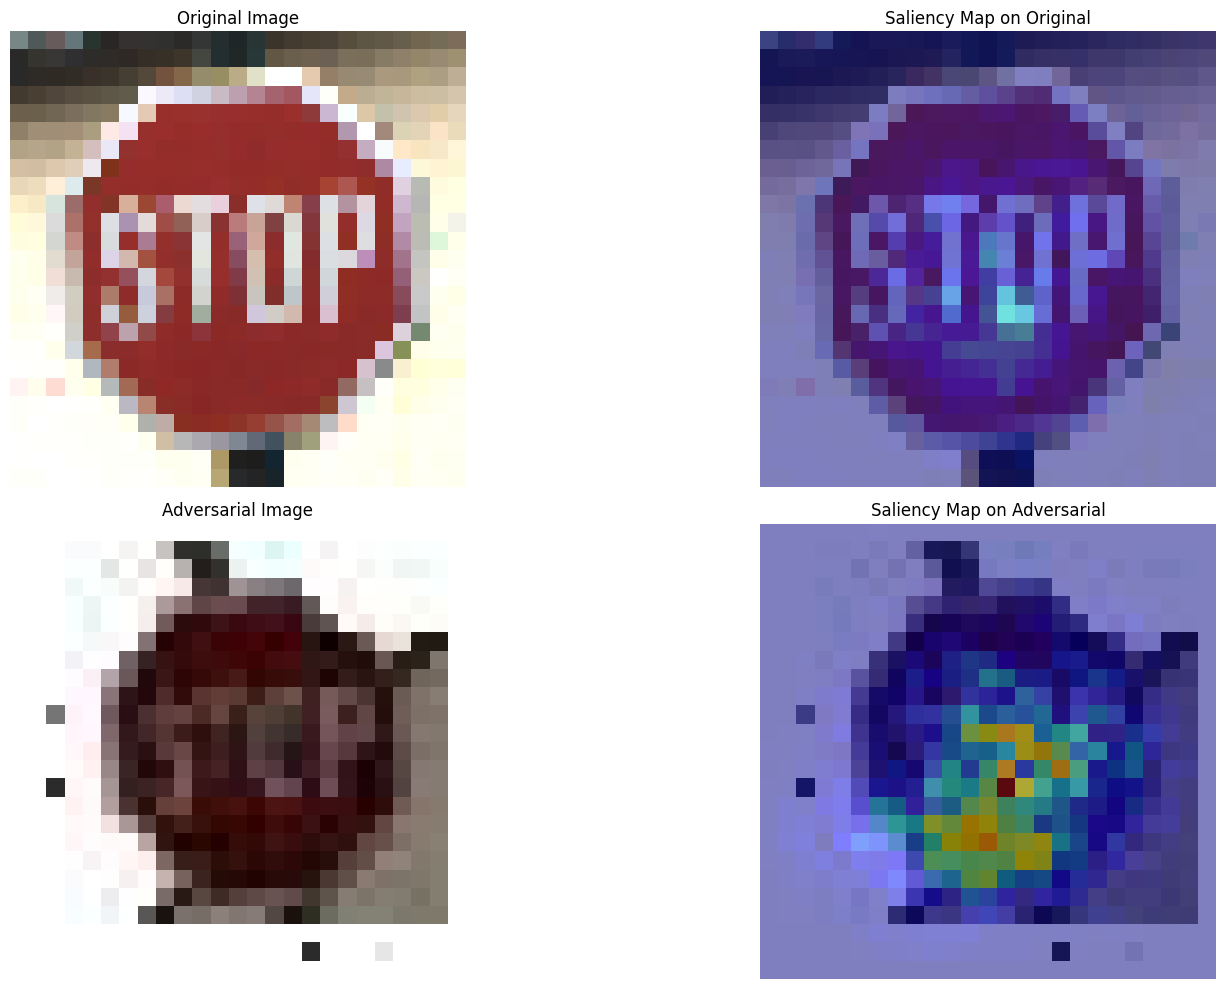

In [ ]:
# --- Step 11: Plot all images and maps ---
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

axes[0,0].imshow(x[0])
axes[0,0].set_title("Original Image")
axes[0,0].axis('off')

axes[0,1].imshow(overlay_orig)
axes[0,1].set_title("Saliency Map on Original")
axes[0,1].axis('off')

axes[1,0].imshow(adversarial_x[0])
axes[1,0].set_title("Adversarial Image")
axes[1,0].axis('off')

axes[1,1].imshow(overlay_adv)
axes[1,1].set_title("Saliency Map on Adversarial")
axes[1,1].axis('off')

plt.tight_layout()
plt.show()